# M4 exploration - Salmon lice pipeline
Question: how often do reported cohort weeks reach fixed adult-female lice thresholds,
and how much do the answer and farm rankings depend on coverage, summaries and flags?
This source covers M4 sections 2.1-2.4 and is followed by Egemen's sections 2.5-2.7.
Fixed 0.2/0.5 thresholds are analytical, not farm-specific legal limits.

In [1]:
from pathlib import Path
from dataclasses import asdict
import json
import os
import sys

ROOT = next((p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/db.py').is_file()),None)
if ROOT is None:
    raise RuntimeError('Start from the repository root or notebooks directory')
sys.path.insert(0,str(ROOT/'src'))
from explore import (Parameters, connect_ro, snapshot_all, query, bindings, coverage,
                     group_summaries, LookLog, table, style, save_figure, write_json)
import numpy as np
import matplotlib.pyplot as plt

# All analysis choices live here. Paths can be overridden for disposable verification.
PARAMS = Parameters(
    cohort=tuple(int(v) for v in (ROOT/'config/cohort.txt').read_text().split()),
    start_year=2022, end_year=2025, thresholds=(0.2,0.5),
    primary_lice_flags=('ok','unusual_high','unusual_low'), strict_lice_flags=('ok',),
    primary_temperature_flags=('ok','unusual_high','unusual_low','suspect_stuck','suspect_spike'),
    strict_temperature_flags=('ok',), min_coverage=0.75,
    histogram_widths=(0.05,0.1,0.2), selected_histogram_width=0.1,
    temperature_edges=(-5.,4.,8.,12.,16.,20.,40.), seed=42, bootstrap_replicates=2000,
    min_time_farms=20, time_block_weeks=13, min_block_coverage=0.5,
    spring_windows=((16,21),(21,26)), relationship_bin_c=2.0, upper_tail_quantile=0.99,
    cold_range_c=(4.,8.), warm_range_c=(12.,16.), min_regime_weeks=6, min_overlap_farms=3,
    min_stratum_regime_weeks=2,
)
DB_PATH = Path(os.environ.get('M4_DB_PATH',str(ROOT/'data/salmon_lice.db')))
FIGURE_DIR = Path(os.environ.get('M4_FIGURE_DIR',str(ROOT/'figures')))
EVIDENCE_DIR = Path(os.environ.get('M4_EVIDENCE_DIR',str(ROOT/'docs/evidence')))
FIGURE_DIR.mkdir(parents=True,exist_ok=True)
EVIDENCE_DIR.mkdir(parents=True,exist_ok=True)
np.random.seed(PARAMS.seed)
style()
con = connect_ro(DB_PATH)
before = snapshot_all(con)
look_log = LookLog()
results = {'parameters':asdict(PARAMS),'scope':'Full M4 exploration, sections 2.1-2.7'}
flag_caption = ' + '.join(PARAMS.primary_lice_flags)
period_caption = str(PARAMS.start_year)+'-'+str(PARAMS.end_year)
threshold_caption = ' and '.join(str(t) for t in PARAMS.thresholds)
coverage_label = f'{100*PARAMS.min_coverage:g}%'
print(json.dumps(asdict(PARAMS),indent=2))
print('Read-only database; initial table hashes:',len(before))
print('Primary period: complete source years 2022-2025; source year/week assumed ISO.')
print('Main groups: locality, year and configured temperature bands; no inferred county groups.')
print('Available-report summaries have no minimum coverage; comparative farm summaries require >=75% per farm-year.')

{
  "cohort": [
    10110,
    10262,
    10292,
    10324,
    10328,
    11290,
    11312,
    11350,
    11405,
    11800,
    11922,
    12244,
    12652,
    12660,
    12714,
    12855,
    12897,
    13226,
    13229,
    13870,
    20316,
    20559,
    22095,
    26955,
    29816,
    30517,
    31497,
    31557,
    31757,
    33197,
    33617,
    34457,
    35377,
    35617,
    36077,
    36517,
    36737,
    37357,
    45017,
    45025
  ],
  "start_year": 2022,
  "end_year": 2025,
  "thresholds": [
    0.2,
    0.5
  ],
  "primary_lice_flags": [
    "ok",
    "unusual_high",
    "unusual_low"
  ],
  "strict_lice_flags": [
    "ok"
  ],
  "primary_temperature_flags": [
    "ok",
    "unusual_high",
    "unusual_low",
    "suspect_stuck",
    "suspect_spike"
  ],
  "strict_temperature_flags": [
    "ok"
  ],
  "min_coverage": 0.75,
  "histogram_widths": [
    0.05,
    0.1,
    0.2
  ],
  "selected_histogram_width": 0.1,
  "temperature_edges": [
    -5.0,
    4.0,
    8.0

## 2.1 Raw versus cleaned: the same question and explicit denominators
What share of reported cohort weeks reaches each fixed analytical threshold?
Primary filters retain unusual lice values: they can be real infestations.
Raw-matched-strict uses raw values on the exact keys accepted by the strict clean filter,
separating a filter/population change from a numeric cleaning change.
Available reports are the denominator; absent weeks are not zero-valued observations.

In [2]:
key_results = []
print((ROOT/'sql/queries/m4_cagatay_key_number.sql').read_text(encoding='utf-8'))
for threshold in PARAMS.thresholds:
    for label, layer, flags in (
        ('raw','raw',PARAMS.primary_lice_flags),
        ('clean_primary','clean',PARAMS.primary_lice_flags),
        ('clean_strict','clean',PARAMS.strict_lice_flags),
        ('raw_matched_strict','raw_matched',PARAMS.strict_lice_flags),
    ):
        arguments = dict(bindings(PARAMS,flags,threshold),layer=layer)
        estimate = query(con,'m4_cagatay_key_number.sql',arguments)[0]
        key_results.append(dict(estimate,threshold=threshold,layer=label,
                               flags='none (M2)' if label=='raw' else ','.join(flags)))
        look_log.add('C-KEY-'+str(threshold)+'-'+label,
                     'Share of available reports reaching the analytical threshold',
                     {'layer':label,'threshold':threshold,'flags':list(flags) if label!='raw' else [],
                      'period':[PARAMS.start_year,PARAMS.end_year],'n':estimate['n'],'coverage_rule':'available reports; no minimum'})
table(key_results,['threshold','layer','flags','n','reaching_threshold','share','mean_lice'])
results['key_numbers'] = key_results

-- Question: what share of reported cohort weeks reaches a fixed analytical threshold?
-- Grain: one result for one layer/flag filter/threshold over the configured complete years.
-- Raw has no flags; raw_matched applies the selected clean-key filter to raw values.
-- Clean uses exactly flags_json. Available reports are the denominator, never missing weeks.
WITH observations AS (
    SELECT CASE WHEN :layer IN ('raw', 'raw_matched') THEN r.avg_adult_female_lice
                ELSE c.avg_adult_female_lice END AS value
    FROM lice_weekly r
    JOIN locality l USING (locality_key)
    JOIN lice_weekly_clean c USING (locality_key, year, week)
    WHERE l.locality_no IN (SELECT value FROM json_each(:cohort_json))
      AND r.year BETWEEN :start_year AND :end_year
      AND (:layer = 'raw' OR c.avg_adult_female_lice_flag IN (SELECT value FROM json_each(:flags_json)))
)
SELECT COUNT(value) AS n,
       COALESCE(SUM(CASE WHEN value >= :threshold THEN 1 ELSE 0 END), 0) AS reaching_threshold,

## 2.2 Which summary answers which question?
Share >= threshold answers frequency among reports. The median answers the typical reported
lice burden; p95 answers upper-tail burden. These need not rank farms alike.
Primary comparative rankings require >=75% calendar reporting coverage in each included farm-year.
Farm-years failing coverage remain visible in the unrestricted sensitivity table, not deleted from DB.

In [3]:
primary_rows = query(con,'m4_cagatay_observations.sql',bindings(PARAMS))
rank_results = {}
for threshold in PARAMS.thresholds:
    grid = coverage(con,PARAMS,threshold=threshold)
    eligible_keys = {(r['locality_no'],r['year']) for r in grid if r['eligible'] and r['year']<=PARAMS.end_year}
    qualified_rows = [r for r in primary_rows if (r['locality_no'],r['year']) in eligible_keys]
    qualified = group_summaries(qualified_rows,threshold)
    unrestricted = group_summaries(primary_rows,threshold)
    differences = sum(r['share_rank']!=r['median_rank'] for r in qualified)
    rank_results[str(threshold)] = {'qualified':qualified,'unrestricted':unrestricted,
        'qualified_n':len(qualified_rows),'qualified_farm_years':len(eligible_keys),
        'different_share_median_ranks':differences}
    print('Threshold',threshold,'qualified farm-year coverage >=',PARAMS.min_coverage)
    table(qualified,['locality_no','n','share','median','p95','share_rank','median_rank','p95_rank'])
    print('Available-report sensitivity, no minimum farm-year coverage:')
    table(unrestricted,['locality_no','n','share','median','p95','share_rank','median_rank','p95_rank'])
    print('Different share-versus-median competition ranks:',differences,'of',len(qualified))
    look_log.add('C-RANK-'+str(threshold),'Do frequency, typical burden and upper-tail burden rank farms alike?',
                 {'threshold':threshold,'summaries':['share','median','p95'],'min_farm_year_coverage':PARAMS.min_coverage,
                  'n':len(qualified_rows),'farms':len(qualified),'alternative_no_coverage_n':len(primary_rows),
                  'flag_filter':list(PARAMS.primary_lice_flags)})
results['rankings'] = rank_results

Threshold 0.2 qualified farm-year coverage >= 0.75
| locality_no | n | share | median | p95 | share_rank | median_rank | p95_rank |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 11800 | 102 | 0.578431 | 0.23 | 0.46 | 1 | 1 | 13 |
| 36737 | 91 | 0.527473 | 0.21 | 0.45 | 2 | 2 | 16 |
| 12652 | 92 | 0.467391 | 0.186363 | 0.462689 | 3 | 3 | 12 |
| 12660 | 104 | 0.451923 | 0.165306 | 0.468214 | 4 | 8 | 11 |
| 10110 | 97 | 0.443299 | 0.18 | 0.424 | 5 | 4 | 17 |
| 12897 | 136 | 0.441176 | 0.175 | 0.86 | 6 | 5 | 3 |
| 37357 | 102 | 0.431373 | 0.169063 | 0.37119 | 7 | 7 | 25 |
| 12244 | 95 | 0.421053 | 0.17 | 0.4 | 8 | 6 | 22 |
| 10262 | 39 | 0.384615 | 0.14375 | 0.469762 | 9 | 11 | 10 |
| 31497 | 52 | 0.384615 | 0.135 | 2.0005 | 9 | 12 | 2 |
| 26955 | 92 | 0.380435 | 0.155 | 0.419 | 11 | 10 | 18 |
| 36077 | 91 | 0.362637 | 0.161111 | 0.403571 | 12 | 9 | 21 |
| 31757 | 130 | 0.346154 | 0.11 | 0.4855 | 13 | 15 | 5 |
| 13229 | 145 | 0.331034 | 0.1 | 0.656 | 14 | 17 | 4 |
| 20559 | 104 | 0.3

## 2.3 Shape: histogram widths and an ECDF answer different questions
Histograms show local concentration but depend on bin width. ECDFs show all empirical
cumulative mass without bins. All available, primary-filter reports in 2022-2025 are used;
no minimum coverage is imposed for these descriptive shapes. Group panels are years,
while all 40 farm distributions are summarised numerically above.

Shape: {'n': 6004, 'min': 0.0, 'median': 0.07999999821186066, 'mean': 0.14789907993554363, 'p95': 0.4399999976158142, 'max': 5.683333396911621, 'zeros': 1339}


Figure: m4_cagatay_shape_overall.png


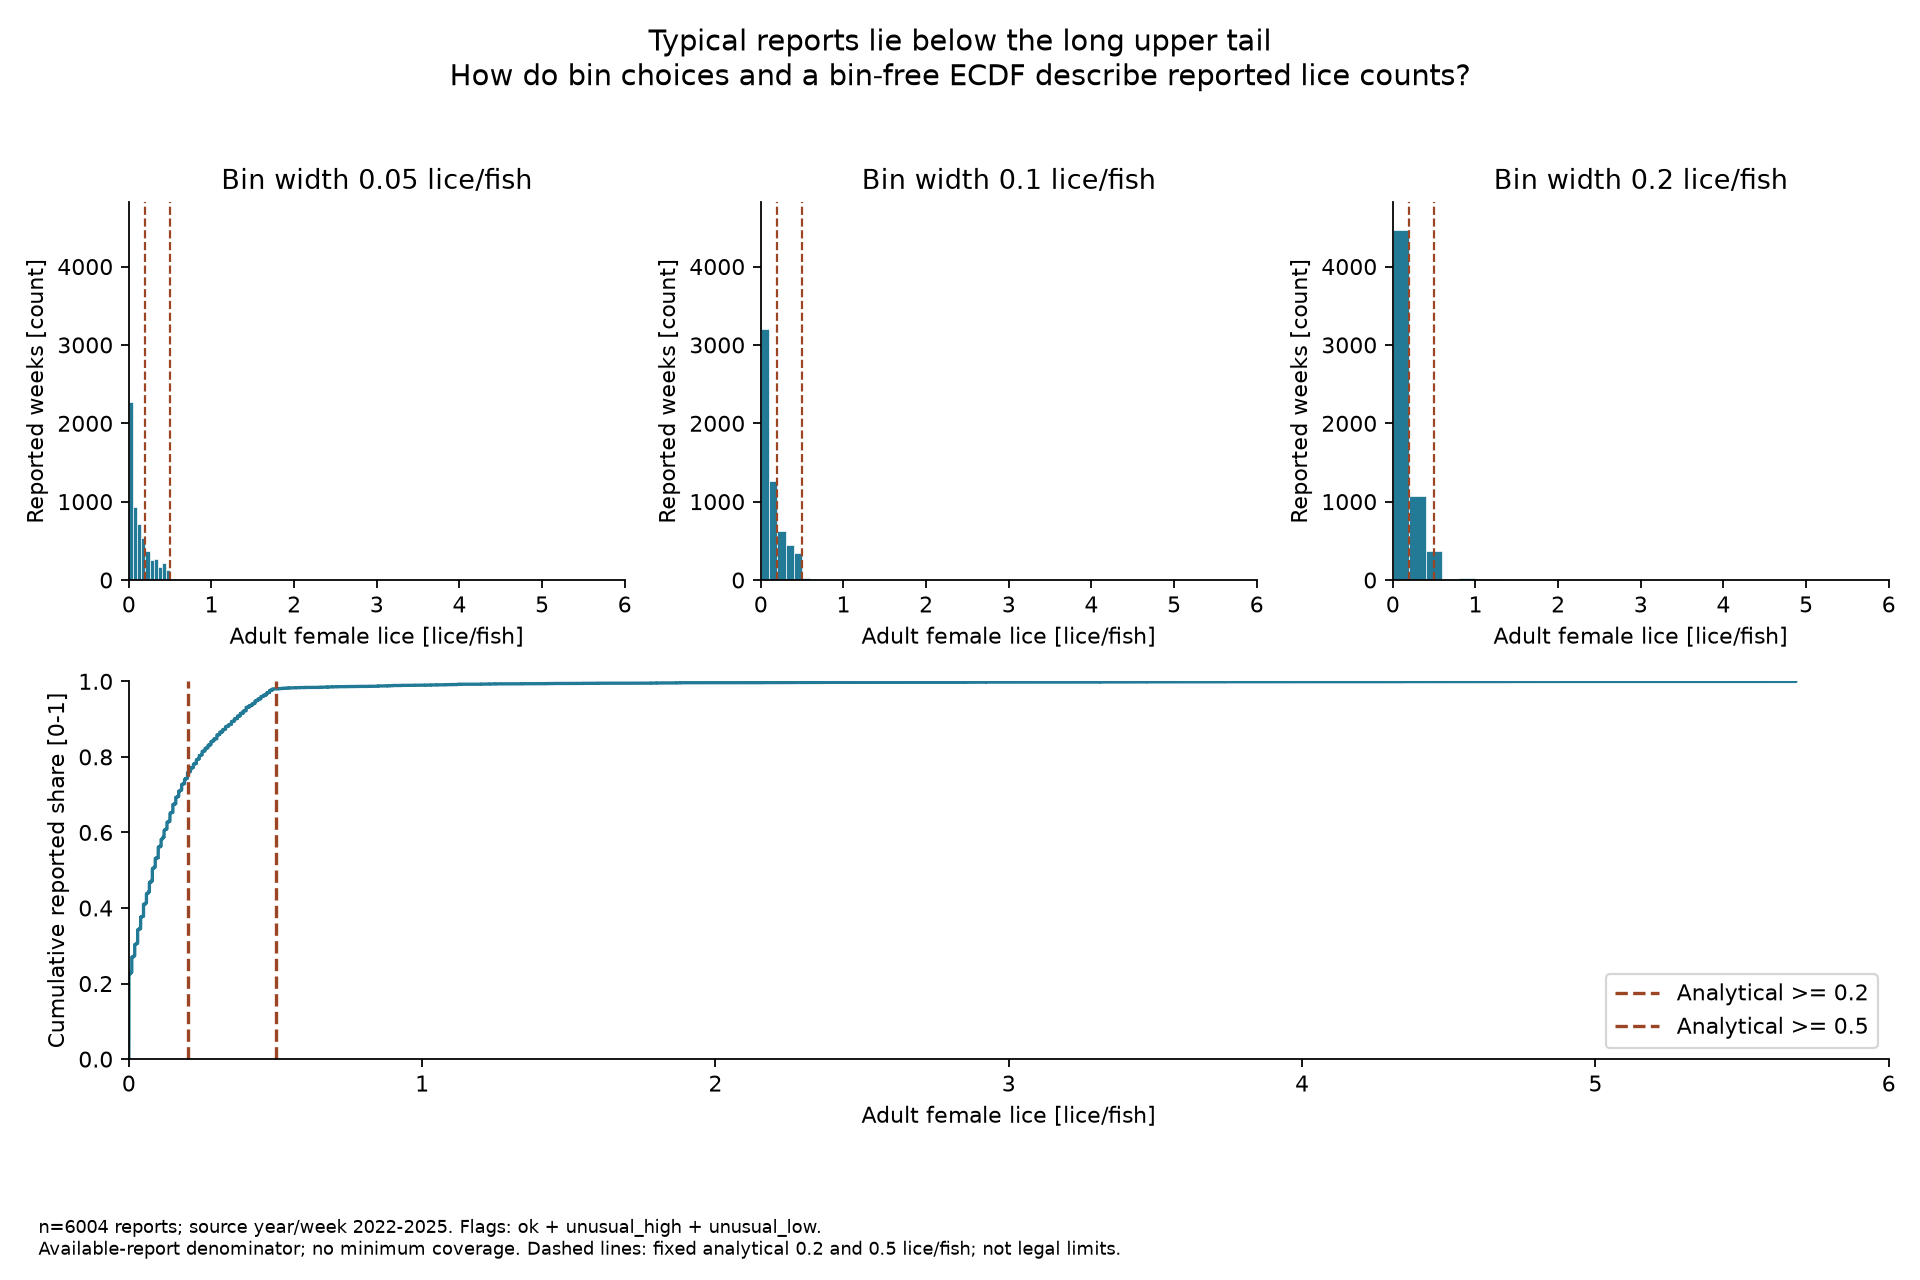

WindowsPath('C:/Users/Çağatay/Desktop/salmon-lice-pipeline/figures/m4_cagatay_shape_overall.png')

In [4]:
values = np.asarray([row['value'] for row in primary_rows])
shape_summary = {'n':len(values),'min':float(values.min()),'median':float(np.median(values)),
                 'mean':float(values.mean()),'p95':float(np.quantile(values,.95)),
                 'max':float(values.max()),'zeros':int(np.sum(values==0))}
results['shape'] = shape_summary
print('Shape:',shape_summary)
fig = plt.figure(figsize=(12,8))
layout = fig.add_gridspec(2,3)
hist_axes = []
common_right = float(np.ceil((values.max()+max(PARAMS.histogram_widths))/max(PARAMS.histogram_widths))*max(PARAMS.histogram_widths))
common_peak = max(int(np.histogram(values,bins=np.arange(0,common_right+width/2,width))[0].max()) for width in PARAMS.histogram_widths)
for index,width in enumerate(PARAMS.histogram_widths):
    ax = fig.add_subplot(layout[0,index],sharey=hist_axes[0] if hist_axes else None)
    hist_axes.append(ax)
    edges = np.arange(0,common_right+width/2,width)
    ax.hist(values,bins=edges,color='#237a97',edgecolor='white',linewidth=.3)
    ax.set(title='Bin width '+str(width)+' lice/fish',xlabel='Adult female lice [lice/fish]',ylabel='Reported weeks [count]')
    ax.set_xlim(0,common_right); ax.set_ylim(0,common_peak*1.08)
    for threshold in PARAMS.thresholds:
        ax.axvline(threshold,color='#9c4524',linestyle='--',linewidth=1)
    look_log.add('C-HIST-'+str(width),'Does histogram bin width change the apparent lice-count shape?',
                 {'width_lice_per_fish':width,'n':len(values),'flag_filter':list(PARAMS.primary_lice_flags),'coverage_rule':'available reports; no minimum'})
ax = fig.add_subplot(layout[1,:])
ordered = np.sort(values)
ax.step(ordered,np.arange(1,len(ordered)+1)/len(ordered),where='post',color='#237a97')
ax.set(xlabel='Adult female lice [lice/fish]',ylabel='Cumulative reported share [0-1]',xlim=(0,common_right),ylim=(0,1))
for threshold in PARAMS.thresholds:
    ax.axvline(threshold,color='#9c4524',linestyle='--',label='Analytical >= '+str(threshold))
ax.legend(loc='lower right')
save_figure(fig,FIGURE_DIR,'m4_cagatay_shape_overall.png',
            'Typical reports lie below the long upper tail',
            'How do bin choices and a bin-free ECDF describe reported lice counts?',
            'n='+str(len(values))+' reports; source year/week '+period_caption+'. Flags: '+flag_caption+'.\n'
            'Available-report denominator; no minimum coverage. Dashed lines: fixed analytical '+threshold_caption+' lice/fish; not legal limits.')

### Are the yearly distributions interchangeable?
Same axes and bin widths across years prevent scale-driven visual differences.
Histogram bar heights are fractions of that year's n, and every ECDF uses its own n.

| year | n | median | p95 |
| --- | --- | --- | --- |
| 2022 | 1503 | 0.07 | 0.45 |
| 2023 | 1550 | 0.07 | 0.37 |
| 2024 | 1352 | 0.1 | 0.4445 |
| 2025 | 1599 | 0.1 | 0.46 |


Figure: m4_cagatay_shape_years.png


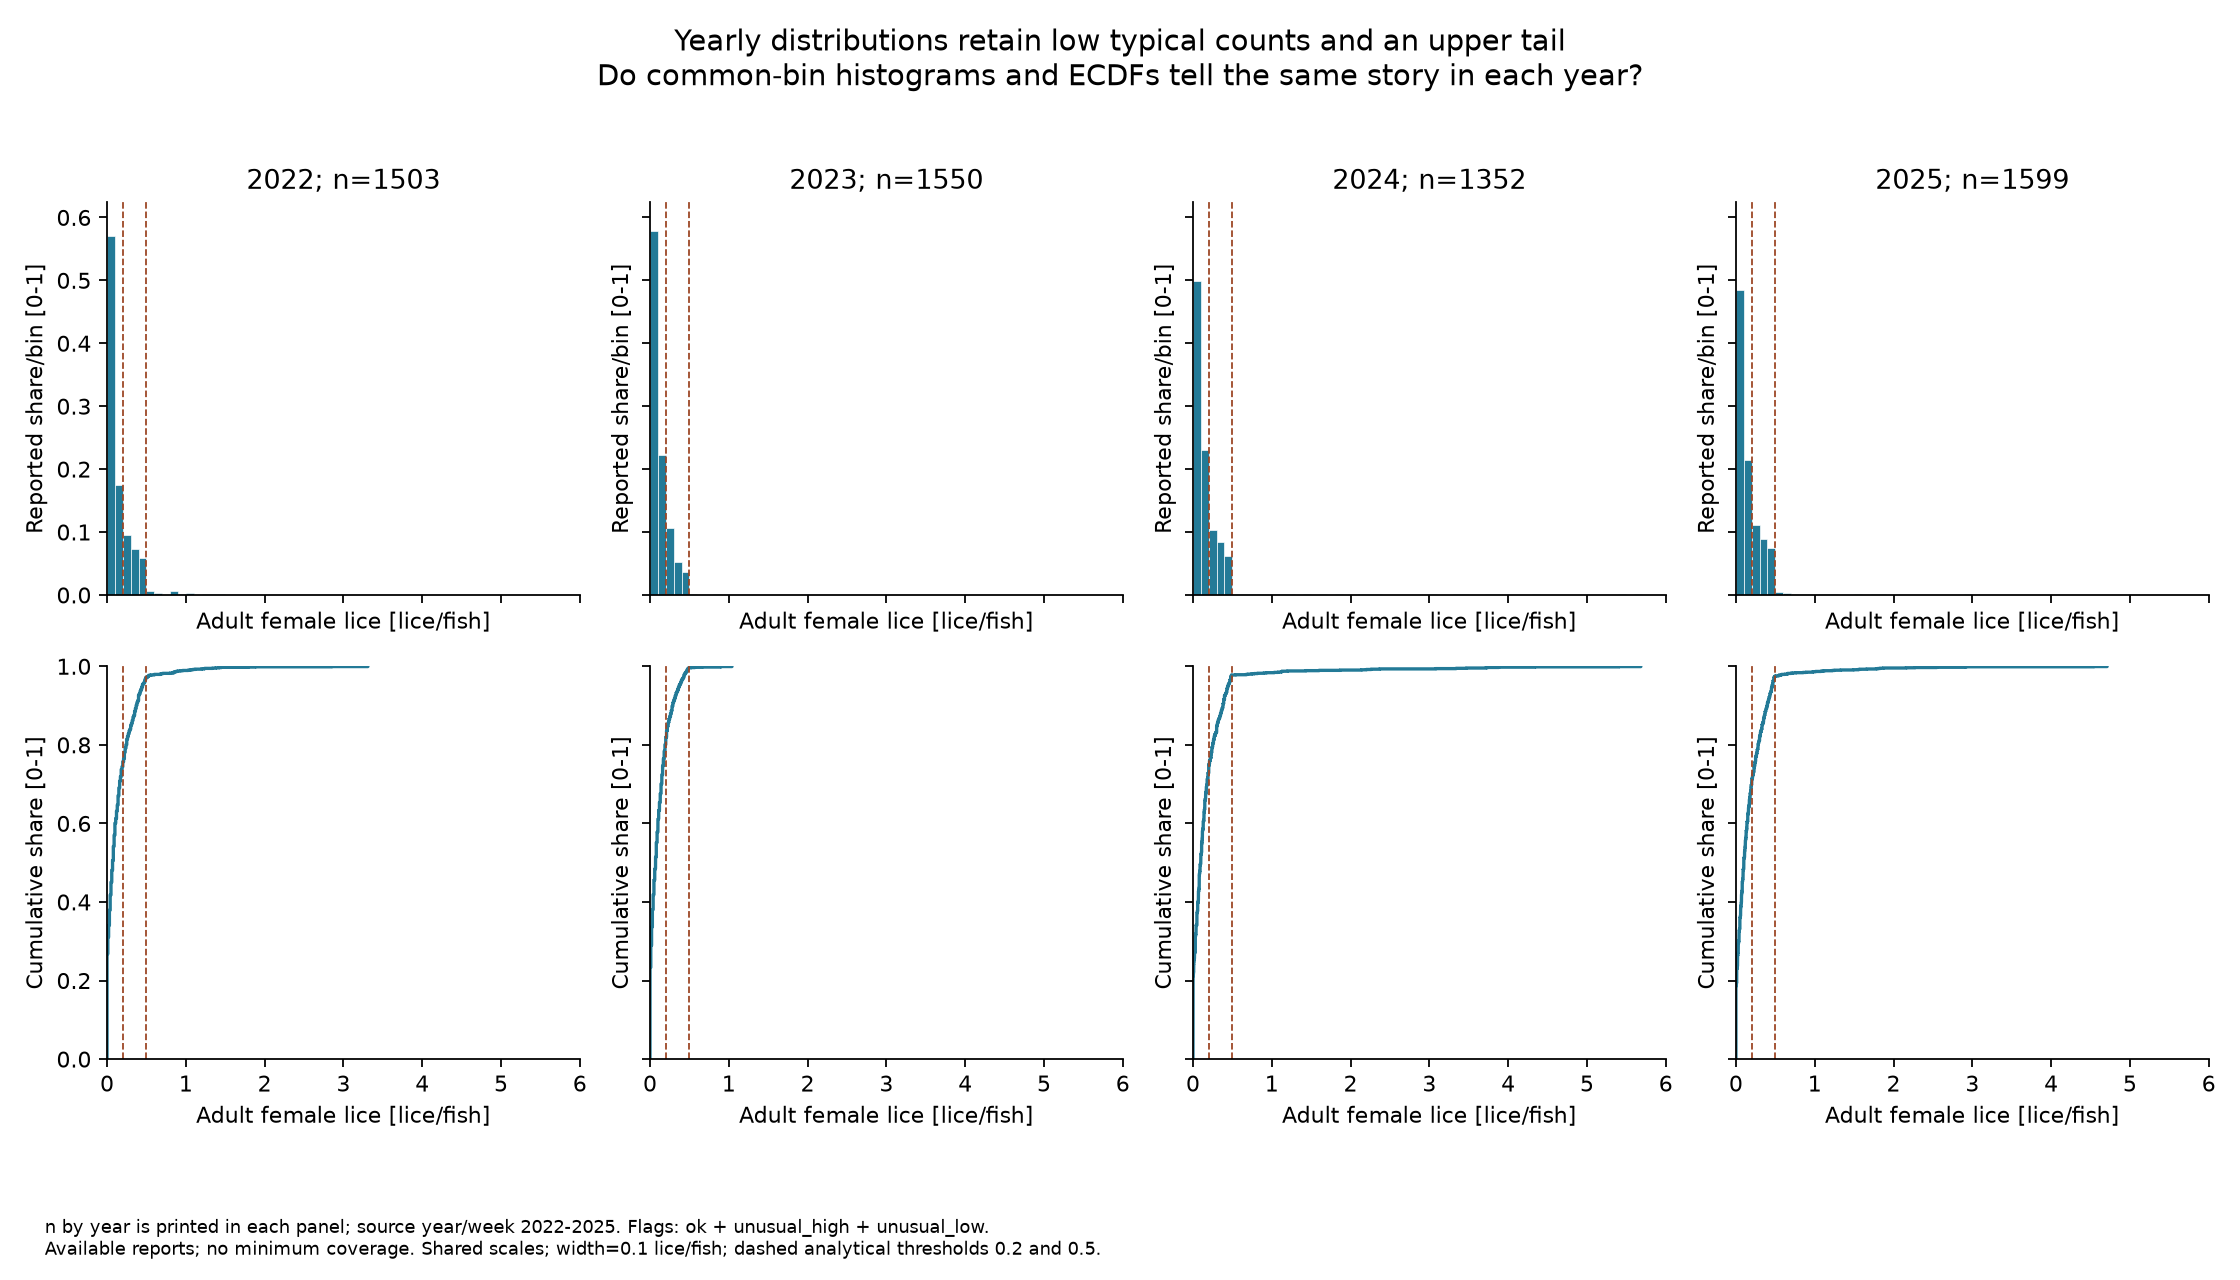

WindowsPath('C:/Users/Çağatay/Desktop/salmon-lice-pipeline/figures/m4_cagatay_shape_years.png')

In [5]:
years = list(range(PARAMS.start_year,PARAMS.end_year+1))
fig, axes = plt.subplots(2,len(years),figsize=(14,8),sharex=True,sharey='row',squeeze=False)
width = PARAMS.selected_histogram_width
edges = np.arange(0,common_right+width/2,width)
year_shapes = []
year_peak = 0.
for column,year in enumerate(years):
    yearly = np.asarray([row['value'] for row in primary_rows if row['year']==year])
    if not len(yearly):
        for ax in axes[:,column]:
            ax.text(.5,.5,'No reports',transform=ax.transAxes,ha='center')
        continue
    year_shapes.append({'year':year,'n':len(yearly),'median':float(np.median(yearly)),'p95':float(np.quantile(yearly,.95))})
    year_peak = max(year_peak,float(np.histogram(yearly,bins=edges)[0].max()/len(yearly)))
    axes[0,column].hist(yearly,bins=edges,weights=np.ones(len(yearly))/len(yearly),color='#237a97',edgecolor='white',linewidth=.3)
    axes[0,column].set(title=str(year)+'; n='+str(len(yearly)),ylabel='Reported share/bin [0-1]',ylim=(0,None))
    axes[1,column].step(np.sort(yearly),np.arange(1,len(yearly)+1)/len(yearly),where='post',color='#237a97')
    axes[1,column].set(ylabel='Cumulative share [0-1]',ylim=(0,1))
    for ax in axes[:,column]:
        ax.set_xlabel('Adult female lice [lice/fish]')
        ax.set_xlim(0,common_right)
        for threshold in PARAMS.thresholds:
            ax.axvline(threshold,color='#9c4524',linestyle='--',linewidth=.8)
    look_log.add('C-SHAPE-YEAR-'+str(year),'How does the annual lice-count distribution differ?',
                 {'year':year,'n':len(yearly),'histogram_width':width,'flag_filter':list(PARAMS.primary_lice_flags),'coverage_rule':'available reports; no minimum'})
table(year_shapes,['year','n','median','p95'])
for ax in axes[0,:]:
    ax.set_ylim(0,year_peak*1.08)
results['year_shapes'] = year_shapes
save_figure(fig,FIGURE_DIR,'m4_cagatay_shape_years.png',
            'Yearly distributions retain low typical counts and an upper tail',
            'Do common-bin histograms and ECDFs tell the same story in each year?',
            'n by year is printed in each panel; source year/week '+period_caption+'. Flags: '+flag_caption+'.\n'
            'Available reports; no minimum coverage. Shared scales; width='+str(width)+' lice/fish; dashed analytical thresholds '+threshold_caption+'.')

## 2.4 Coverage, denominator and flag sensitivity
How many calendar reporting opportunities contribute to each farm-year estimate?
Calendar opportunities are not evidence that fish were present or reporting was required.
2026 coverage ends at the last completed week at retrieval and is not pooled with full years.
At least 75% coverage supports the comparative ranking; lower-coverage data remain visible.

| locality_no | year | n | expected_weeks | coverage | eligible |
| --- | --- | --- | --- | --- | --- |
| 10110 | 2022 | 52 | 52 | 1 | True |
| 10110 | 2023 | 33 | 52 | 0.634615 | False |
| 10110 | 2024 | 45 | 52 | 0.865385 | True |
| 10110 | 2025 | 27 | 52 | 0.519231 | False |
| 10110 | 2026 | 40 | 40 | 1 | True |
| 10262 | 2022 | 33 | 52 | 0.634615 | False |
| 10262 | 2023 | 37 | 52 | 0.711538 | False |
| 10262 | 2024 | 39 | 52 | 0.75 | True |
| 10262 | 2025 | 28 | 52 | 0.538462 | False |
| 10262 | 2026 | 27 | 40 | 0.675 | False |
| 10292 | 2022 | 34 | 52 | 0.653846 | False |
| 10292 | 2023 | 45 | 52 | 0.865385 | True |
| 10292 | 2024 | 30 | 52 | 0.576923 | False |
| 10292 | 2025 | 27 | 52 | 0.519231 | False |
| 10292 | 2026 | 18 | 40 | 0.45 | False |
| 10324 | 2022 | 35 | 52 | 0.673077 | False |
| 10324 | 2023 | 41 | 52 | 0.788462 | True |
| 10324 | 2024 | 18 | 52 | 0.346154 | False |
| 10324 | 2025 | 41 | 52 | 0.788462 | True |
| 10324 | 2026 | 2 | 40 | 0.05 | False |
| 10328 | 202

Figure: m4_cagatay_coverage.png


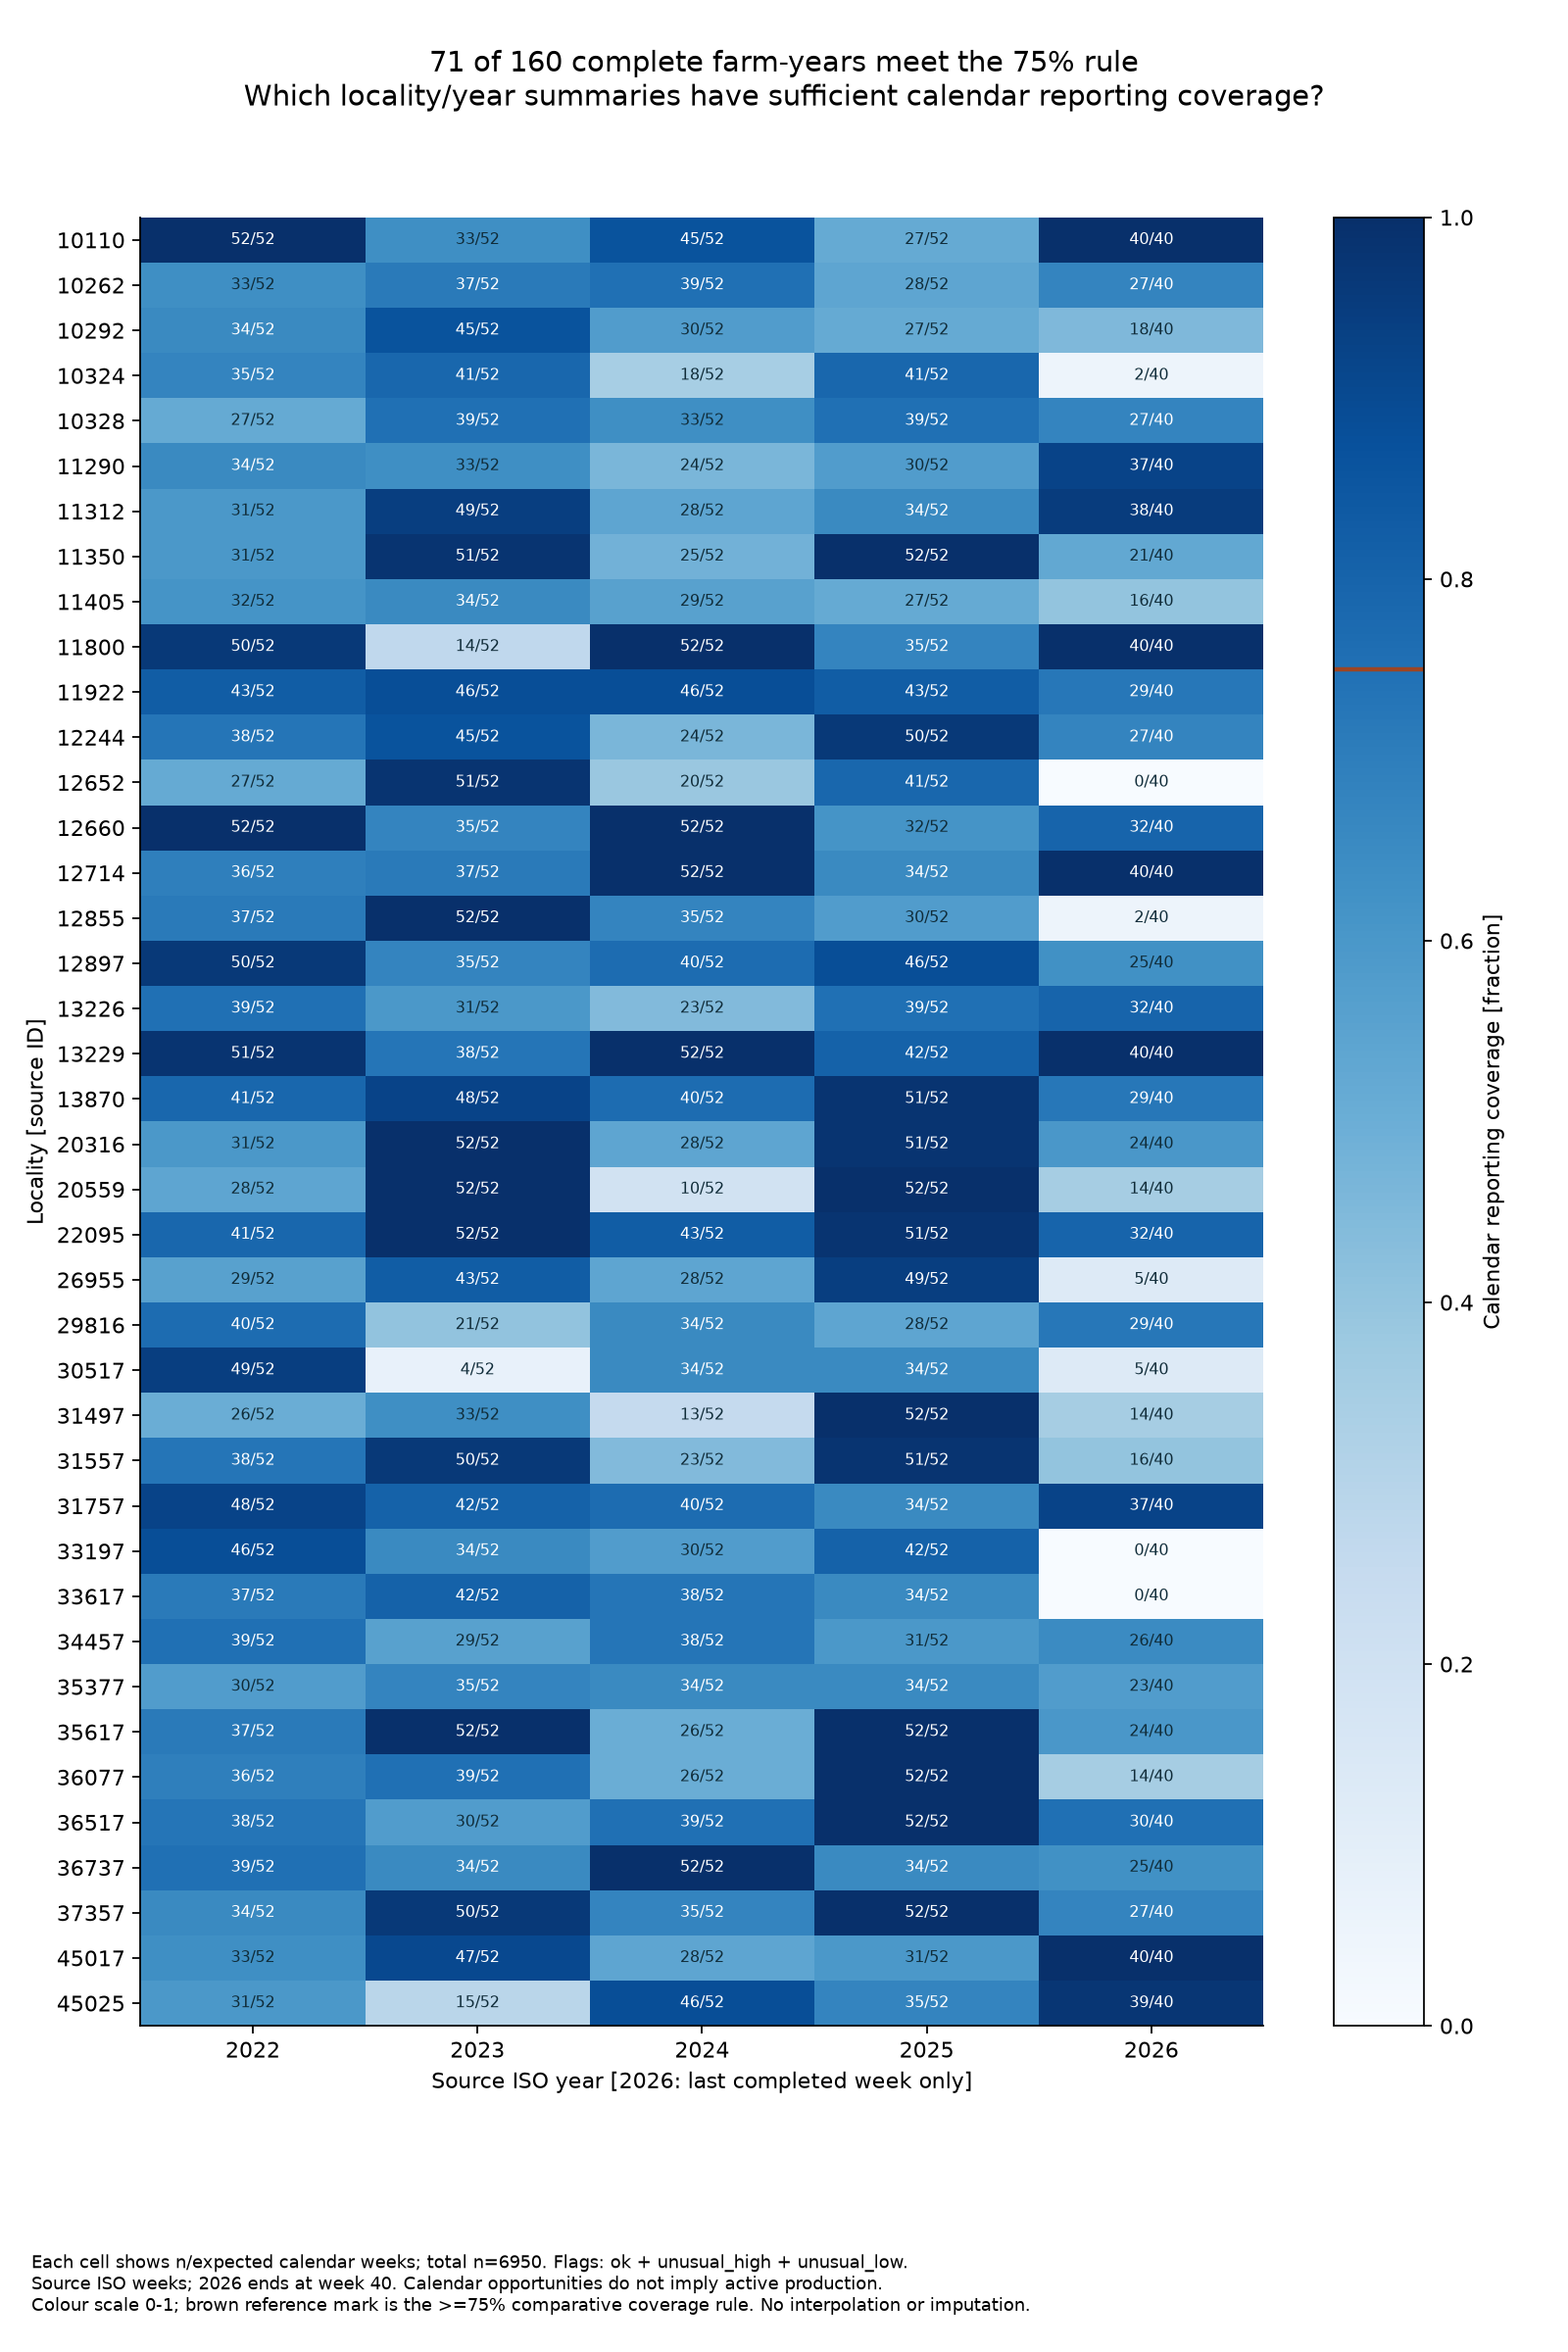

WindowsPath('C:/Users/Çağatay/Desktop/salmon-lice-pipeline/figures/m4_cagatay_coverage.png')

In [6]:
coverage_grid = coverage(con,PARAMS)
table(coverage_grid,['locality_no','year','n','expected_weeks','coverage','eligible'])
year_coverage = []
for year in sorted({row['year'] for row in coverage_grid}):
    rows = [r for r in coverage_grid if r['year']==year]
    year_coverage.append({'year':year,'n':sum(r['n'] for r in rows),'calendar_opportunities':sum(r['expected_weeks'] for r in rows),
                          'qualified_farm_years':sum(r['eligible'] for r in rows),'farms':len(rows)})
table(year_coverage,['year','n','calendar_opportunities','qualified_farm_years','farms'])
sensitivity = []
for threshold in PARAMS.thresholds:
    grid = coverage(con,PARAMS,threshold=threshold)
    for label,selected in (
        ('available_reports',[r for r in grid if r['year']<=PARAMS.end_year]),
        (f'coverage_at_least_{100*PARAMS.min_coverage:g}pct',[r for r in grid if r['year']<=PARAMS.end_year and r['eligible']]),
    ):
        n = sum(r['n'] for r in selected)
        exceedances = sum(r['reaching_threshold'] for r in selected)
        sensitivity.append({'threshold':threshold,'rule':label,'farm_years':len(selected),'n':n,
                            'reaching_threshold':exceedances,'share':exceedances/n if n else None})
    look_log.add('C-COVERAGE-'+str(threshold),'Does the minimum farm-year reporting rule change the pooled share?',
                 {'threshold':threshold,'rules':['available_reports','>='+coverage_label+' calendar weeks'],'flag_filter':list(PARAMS.primary_lice_flags)})
table(sensitivity,['threshold','rule','farm_years','n','reaching_threshold','share'])
results['coverage'] = {'grid':coverage_grid,'per_year':year_coverage,'sensitivity':sensitivity}
coverage_years = sorted({row['year'] for row in coverage_grid})
matrix = np.asarray([[next(r['coverage'] for r in coverage_grid if r['locality_no']==number and r['year']==year)
                      for year in coverage_years] for number in PARAMS.cohort])
fig, ax = plt.subplots(figsize=(10,15))
image = ax.imshow(matrix,aspect='auto',cmap='Blues',vmin=0,vmax=1)
ax.set_xticks(range(len(coverage_years)),[str(y) for y in coverage_years])
ax.set_yticks(range(len(PARAMS.cohort)),[str(n) for n in PARAMS.cohort])
ax.set(xlabel='Source ISO year [2026: last completed week only]',ylabel='Locality [source ID]')
for i,number in enumerate(PARAMS.cohort):
    for j,year in enumerate(coverage_years):
        row = next(r for r in coverage_grid if r['locality_no']==number and r['year']==year)
        ax.text(j,i,str(row['n'])+'/'+str(row['expected_weeks']),ha='center',va='center',fontsize=7,
                color='white' if row['coverage']>.65 else '#102c39')
colorbar = fig.colorbar(image,ax=ax,label='Calendar reporting coverage [fraction]')
colorbar.ax.axhline(PARAMS.min_coverage,color='#9c4524',linewidth=2)
complete_grid = [r for r in coverage_grid if r['year']<=PARAMS.end_year]
qualified_count = sum(r['eligible'] for r in complete_grid)
save_figure(fig,FIGURE_DIR,'m4_cagatay_coverage.png',
            str(qualified_count)+' of '+str(len(complete_grid))+' complete farm-years meet the '+coverage_label+' rule',
            'Which locality/year summaries have sufficient calendar reporting coverage?',
            'Each cell shows n/expected calendar weeks; total n='+str(sum(r['n'] for r in coverage_grid))+'. Flags: '+flag_caption+'.\n'
            'Source ISO weeks; 2026 ends at week '+str(coverage_grid[-1]['expected_weeks'])+'. Calendar opportunities do not imply active production.\n'
            'Colour scale 0-1; brown reference mark is the >='+coverage_label+' comparative coverage rule. No interpolation or imputation.')

## 2.5 Time - weekly reporting clock, edges and calendar
Question: how much do reporting coverage and source-week seasonality change summaries?
Reports have year/week, not a measurement hour. UTC retrieved_at is provenance only;
no timezone conversion is invented. ISO Monday positions are a display convention.
The provider confirms weekly reporting but does not explicitly name ISO 8601 in the consulted pages.
Thirteen-week source-year blocks are not Gregorian quarters.

Analytical threshold 0.2 weekly n range 19 36 shown weeks 207 of 208
| year | block | n | expected | shown | share |
| --- | --- | --- | --- | --- | --- |
| 2022 | 1 | 326 | 520 | True | 0.331288 |
| 2022 | 2 | 381 | 520 | True | 0.146982 |
| 2022 | 3 | 421 | 520 | True | 0.289786 |
| 2022 | 4 | 375 | 520 | True | 0.261333 |
| 2023 | 1 | 341 | 520 | True | 0.228739 |
| 2023 | 2 | 404 | 520 | True | 0.0594059 |
| 2023 | 3 | 432 | 520 | True | 0.201389 |
| 2023 | 4 | 373 | 520 | True | 0.321716 |
| 2024 | 1 | 298 | 520 | True | 0.265101 |
| 2024 | 2 | 331 | 520 | True | 0.111782 |
| 2024 | 3 | 363 | 520 | True | 0.289256 |
| 2024 | 4 | 360 | 520 | True | 0.405556 |
| 2025 | 1 | 370 | 520 | True | 0.305405 |
| 2025 | 2 | 424 | 520 | True | 0.127358 |
| 2025 | 3 | 420 | 520 | True | 0.366667 |
| 2025 | 4 | 385 | 520 | True | 0.412987 |
Calendar window only, no region assigned: (16, 21) n 699 reaching 53 share 0.07582260371959942
Calendar window only, no region assigned: (21, 26) n 769 reac

Figure: m4_egemen_time.png


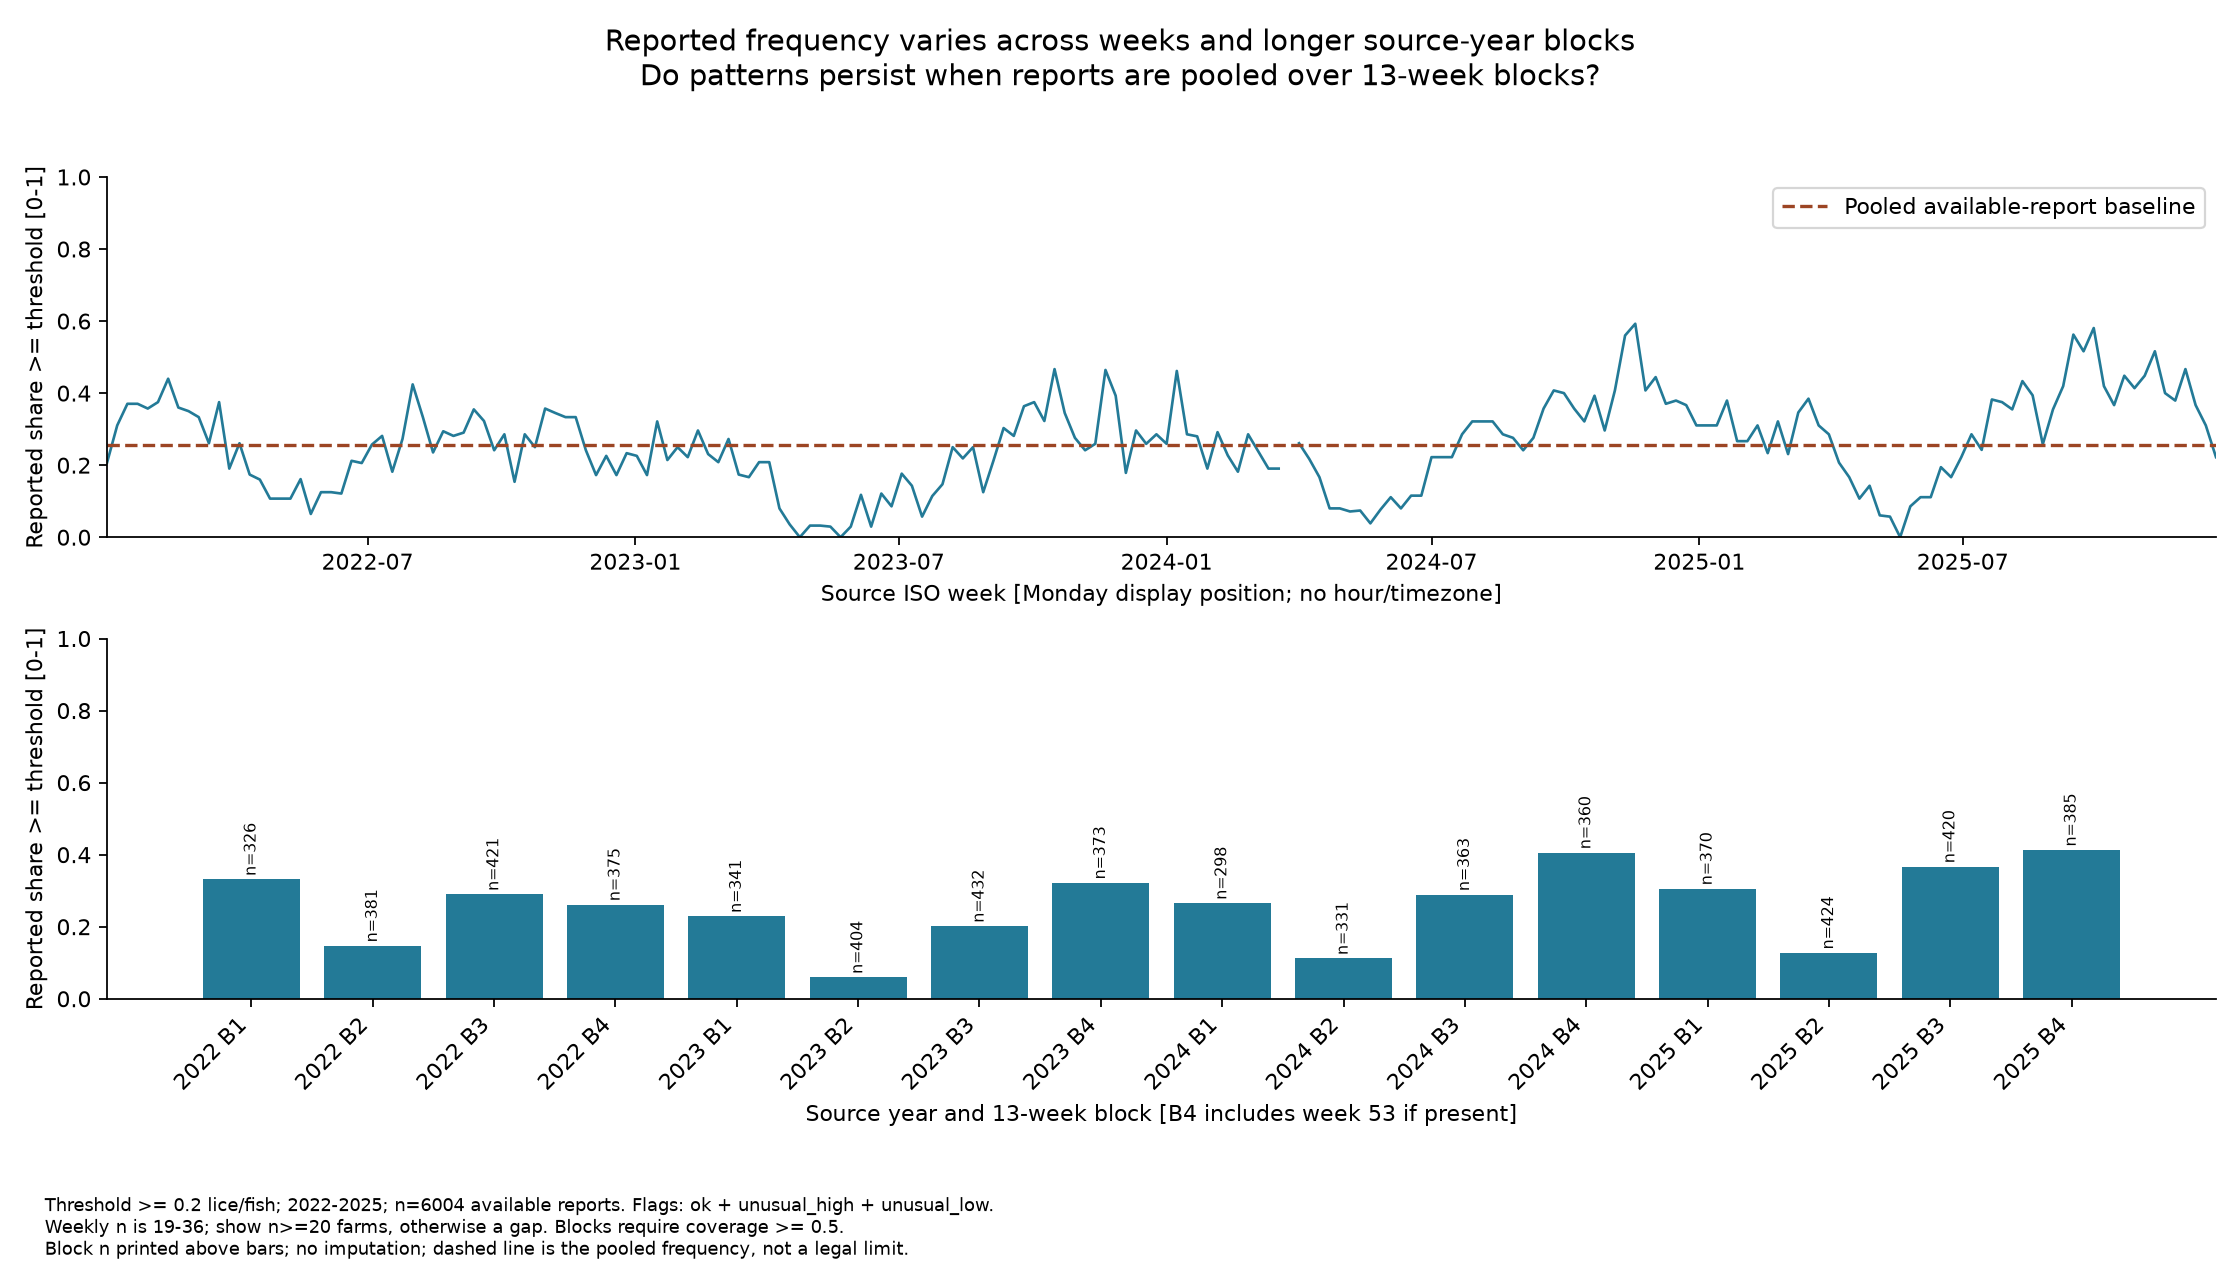

WindowsPath('C:/Users/Çağatay/Desktop/salmon-lice-pipeline/figures/m4_egemen_time.png')

In [7]:
from datetime import date
from explore_egemen import time_tables, paired_reports, correlation, within_group
egemen_results={}
time_results={}
calendar_results=[]
for threshold in PARAMS.thresholds:
    weekly,blocks=time_tables(con,PARAMS,threshold)
    time_results[str(threshold)]={'weekly':weekly,'blocks':blocks}
    print('Analytical threshold',threshold,'weekly n range',min(r['n'] for r in weekly),max(r['n'] for r in weekly),
          'shown weeks',sum(r['shown'] for r in weekly),'of',len(weekly))
    table(blocks,['year','block','n','expected','shown','share'])
    for window in PARAMS.spring_windows:
        members=[r for r in weekly if window[0]<=r['week']<=window[1]]
        n=sum(r['n'] for r in members); reaching=sum(r['reaching_threshold'] for r in members)
        print('Calendar window only, no region assigned:',window,'n',n,'reaching',reaching,'share',reaching/n)
        calendar_results.append({'threshold':threshold,'weeks':window,'n':n,'reaching':reaching,'share':reaching/n})
        look_log.add('E-CALENDAR-'+str(threshold)+'-'+str(window),
                     'What is the descriptive frequency in a documented spring calendar window?',
                     {'threshold':threshold,'weeks':window,'n':n,'flag_filter':list(PARAMS.primary_lice_flags),
                      'coverage_rule':'available reports; windows overlap in week 21; no legal regime assigned'},owner='Mehmet Egemen Karagoz')
    look_log.add('E-TIME-'+str(threshold),'Does a reporting-coverage rule hide thin weekly/block time points?',
                 {'threshold':threshold,'min_weekly_farms':PARAMS.min_time_farms,'min_block_coverage':PARAMS.min_block_coverage,
                  'flag_filter':list(PARAMS.primary_lice_flags),'weekly_shown':sum(r['shown'] for r in weekly)},owner='Mehmet Egemen Karagoz')
edge_rows=con.execute('SELECT year,MIN(week),MAX(week),COUNT(*) FROM lice_weekly_clean GROUP BY year ORDER BY year').fetchall()
print('Source lice edges by year (no filtering for this inventory):',edge_rows)
edge_details=[{'year':year,'first_week_n':next(r['n'] for r in time_results[str(PARAMS.thresholds[0])]['weekly'] if r['year']==year and r['week']==1),
               'last_week_n':next(r['n'] for r in time_results[str(PARAMS.thresholds[0])]['weekly'] if r['year']==year and r['week']==date(year,12,28).isocalendar().week),
               'cohort_farms':len(PARAMS.cohort)} for year in range(PARAMS.start_year,PARAMS.end_year+1)]
table(edge_details,['year','first_week_n','last_week_n','cohort_farms'])
egemen_results['time']={'thresholds':time_results,'source_edges':edge_rows,'edge_coverage':edge_details,'calendar_windows':calendar_results}
main_time=time_results[str(PARAMS.thresholds[0])]
fig,axes=plt.subplots(2,1,figsize=(14,8))
weekly=main_time['weekly']; blocks=main_time['blocks']
axes[0].plot([date.fromisocalendar(r['year'],r['week'],1) for r in weekly],
             [r['share'] if r['shown'] else np.nan for r in weekly],color='#237a97',linewidth=1.2)
axes[0].set(xlabel='Source ISO week [Monday display position; no hour/timezone]',ylabel='Reported share >= threshold [0-1]',ylim=(0,1))
axes[0].set_xlim(date.fromisocalendar(weekly[0]['year'],weekly[0]['week'],1),date.fromisocalendar(weekly[-1]['year'],weekly[-1]['week'],1))
axes[0].axhline(next(r['share'] for r in key_results if r['layer']=='clean_primary' and r['threshold']==PARAMS.thresholds[0]),
                color='#9c4524',linestyle='--',label='Pooled available-report baseline')
axes[0].legend(loc='upper right')
positions=np.arange(len(blocks))
axes[1].bar(positions,[r['share'] if r['shown'] else np.nan for r in blocks],color='#237a97')
axes[1].set_xticks(positions,[str(r['year'])+' B'+str(r['block']) for r in blocks],rotation=45,ha='right')
axes[1].set(xlabel='Source year and 13-week block [B4 includes week 53 if present]',ylabel='Reported share >= threshold [0-1]',ylim=(0,1))
for i,row in enumerate(blocks):
    axes[1].text(i,(row['share'] or 0)+.02,'n='+str(row['n']) if row['shown'] else 'thin',ha='center',fontsize=7,rotation=90)
save_figure(fig,FIGURE_DIR,'m4_egemen_time.png',
            'Reported frequency varies across weeks and longer source-year blocks',
            'Do patterns persist when reports are pooled over 13-week blocks?',
            'Threshold >= '+str(PARAMS.thresholds[0])+' lice/fish; '+period_caption+'; n='+str(sum(r['n'] for r in weekly))+' available reports. Flags: '+flag_caption+'.\n'
            'Weekly n is '+str(min(r['n'] for r in weekly))+'-'+str(max(r['n'] for r in weekly))+'; show n>='+str(PARAMS.min_time_farms)+' farms, otherwise a gap. Blocks require coverage >= '+str(PARAMS.min_block_coverage)+'.\n'
            'Block n printed above bars; no imputation; dashed line is the pooled frequency, not a legal limit.')

## 2.6 Relationship - plot before computing coefficients
Question: is contemporaneous temperature associated with the reported lice burden?
A one-to-one weekly join requires both measurements; no absent report is imputed.
Scatter shows observations; bin medians/IQR show robust conditional summaries, not confidence intervals.

Figure: m4_egemen_relationship.png


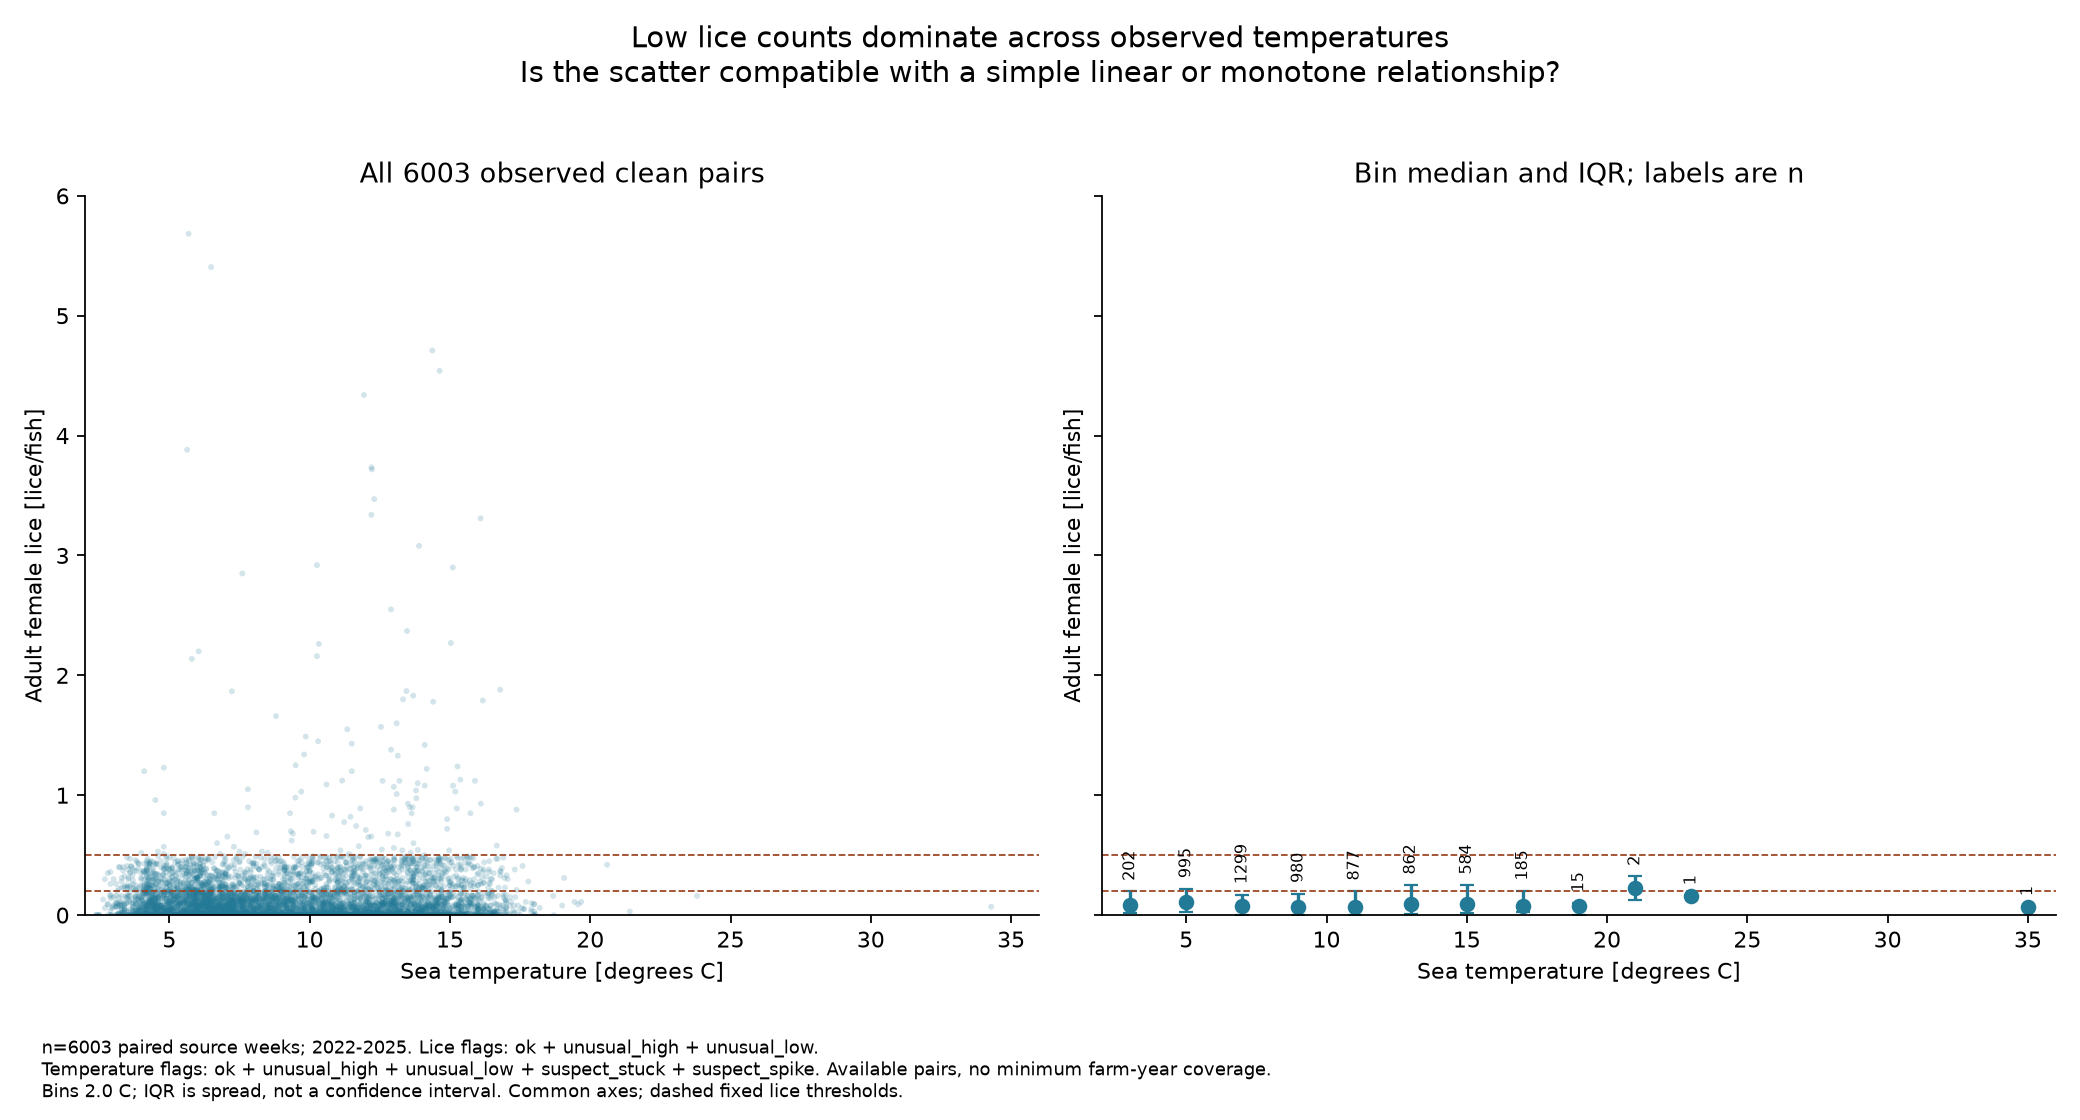

WindowsPath('C:/Users/Çağatay/Desktop/salmon-lice-pipeline/figures/m4_egemen_relationship.png')

In [8]:
paired_primary=paired_reports(con,PARAMS)
paired_raw=paired_reports(con,PARAMS,layer='raw')
paired_strict=paired_reports(con,PARAMS,strict=True)
x=np.asarray([r['temperature'] for r in paired_primary]); y=np.asarray([r['lice'] for r in paired_primary])
bin_edges=np.arange(np.floor(x.min()/PARAMS.relationship_bin_c)*PARAMS.relationship_bin_c,
                    np.ceil(x.max()/PARAMS.relationship_bin_c)*PARAMS.relationship_bin_c+PARAMS.relationship_bin_c/2,
                    PARAMS.relationship_bin_c)
bin_summaries=[]
for left,right in zip(bin_edges,bin_edges[1:]):
    sample=y[(x>=left)&(x<right)]
    if len(sample):
        bin_summaries.append({'left':float(left),'right':float(right),'n':len(sample),
                              'median':float(np.median(sample)),'q1':float(np.quantile(sample,.25)),'q3':float(np.quantile(sample,.75))})
fig,axes=plt.subplots(1,2,figsize=(13,7),sharex=True,sharey=True)
axes[0].scatter(x,y,s=7,alpha=.2,color='#237a97',edgecolors='none')
axes[0].set_title('All '+str(len(x))+' observed clean pairs')
for row in bin_summaries:
    centre=(row['left']+row['right'])/2
    axes[1].errorbar(centre,row['median'],yerr=[[row['median']-row['q1']],[row['q3']-row['median']]],fmt='o',color='#237a97',capsize=3)
    axes[1].text(centre,row['q3']+.12,str(row['n']),ha='center',fontsize=7,rotation=90)
axes[1].set_title('Bin median and IQR; labels are n')
for ax in axes:
    ax.set(xlabel='Sea temperature [degrees C]',ylabel='Adult female lice [lice/fish]',xlim=(bin_edges[0],bin_edges[-1]),ylim=(0,np.ceil(y.max())))
    for threshold in PARAMS.thresholds:
        ax.axhline(threshold,color='#9c4524',linestyle='--',linewidth=.8)
save_figure(fig,FIGURE_DIR,'m4_egemen_relationship.png',
            'Low lice counts dominate across observed temperatures',
            'Is the scatter compatible with a simple linear or monotone relationship?',
            'n='+str(len(paired_primary))+' paired source weeks; '+period_caption+'. Lice flags: '+flag_caption+'.\n'
            'Temperature flags: '+' + '.join(PARAMS.primary_temperature_flags)+'. Available pairs, no minimum farm-year coverage.\n'
            'Bins '+str(PARAMS.relationship_bin_c)+' C; IQR is spread, not a confidence interval. Common axes; dashed fixed lice thresholds.')

### Coefficients and influence checks, after inspecting the plot
Pearson measures a linear association; Spearman a rank/monotone association. Neither
demonstrates causation or predicts future counts. No row-independent p-values are reported.
Removing the top 1% is only a sensitivity diagnostic; it never modifies M3 or the primary estimate.

In [9]:
tail_cutoff=float(np.quantile(y,PARAMS.upper_tail_quantile))
without_tail=[r for r in paired_primary if r['lice']<=tail_cutoff]
lice_flag_by_key={(r['locality_no'],r['year'],r['week']):r['flag'] for r in primary_rows}
strict_lice_only=[r for r in paired_primary if lice_flag_by_key[(r['locality_no'],r['year'],r['week'])] in PARAMS.strict_lice_flags]
variants=[('primary clean pairs',paired_primary),('raw pairs including extreme temperature',paired_raw),
          ('strict lice and temperature flags',paired_strict),('strict lice only; broad temperature',strict_lice_only),
          ('remove upper lice tail',without_tail),('within farm-year centred',within_group(paired_primary,('locality_no','year'))),
          ('within year-week centred',within_group(paired_primary,('year','week')))]
correlations=[]
for label,members in variants:
    estimate=correlation(members,label)
    correlations.append(estimate)
    look_log.add('E-CORR-'+label,'How sensitive are temperature/lice coefficients to flags, extremes and shared structure?',
                 dict(estimate,tail_quantile=PARAMS.upper_tail_quantile,tail_cutoff=tail_cutoff,
                      primary_lice_flags=list(PARAMS.primary_lice_flags),primary_temperature_flags=list(PARAMS.primary_temperature_flags)),owner='Mehmet Egemen Karagoz')
for block in range(1,5):
    members=[r for r in paired_primary if min(3,(r['week']-1)//PARAMS.time_block_weeks)+1==block]
    estimate=correlation(members,'within source-year block '+str(block))
    correlations.append(estimate)
    look_log.add('E-CORR-BLOCK-'+str(block),'Is a pooled association also visible within season blocks?',estimate,owner='Mehmet Egemen Karagoz')
leave_one_out=[]
for number in PARAMS.cohort:
    estimate=correlation([r for r in paired_primary if r['locality_no']!=number],'exclude locality '+str(number))
    leave_one_out.append(dict(estimate,excluded_locality=number))
    look_log.add('E-CORR-EXCLUDE-'+str(number),'Can one locality explain the pooled coefficient?',estimate,owner='Mehmet Egemen Karagoz')
table(correlations,['label','n','pearson','spearman'])
print('Leave-one-farm-out coefficient ranges:',
      {metric:[min(r[metric] for r in leave_one_out),max(r[metric] for r in leave_one_out)] for metric in ('pearson','spearman')})
egemen_results['relationships']={'correlations':correlations,'leave_one_farm_out':leave_one_out,
    'tail_quantile':PARAMS.upper_tail_quantile,'tail_cutoff':tail_cutoff,'tail_removed':len(paired_primary)-len(without_tail),
    'temperature_bins':bin_summaries,'raw_pairs':len(paired_raw),'primary_pairs':len(paired_primary)}
results['egemen']=egemen_results

| label | n | pearson | spearman |
| --- | --- | --- | --- |
| primary clean pairs | 6003 | 0.0635959 | 0.00846181 |
| raw pairs including extreme temperature | 6004 | 0.0510885 | 0.00844011 |
| strict lice and temperature flags | 5855 | 0.0368448 | -0.00745136 |
| strict lice only; broad temperature | 5880 | 0.0362904 | -0.00586021 |
| remove upper lice tail | 5942 | 0.039033 | -0.00389118 |
| within farm-year centred | 6003 | 0.102449 | 0.0960259 |
| within year-week centred | 6003 | -0.0105269 | -0.0329688 |
| within source-year block 1 | 1335 | -0.114001 | -0.168553 |
| within source-year block 2 | 1539 | -0.0211729 | -0.0538837 |
| within source-year block 3 | 1636 | 0.065863 | 0.130958 |
| within source-year block 4 | 1493 | 0.00614293 | -0.0470882 |
Leave-one-farm-out coefficient ranges: {'pearson': [0.04983336755133859, 0.08228584175255728], 'spearman': [-0.0065987767490707635, 0.024608695465027048]}


## 2.7 One comparison with a farm-cluster interval and composition checks
Main comparison, fixed before its outcome calculation: >=0.2 frequency in 12<=T<16 C
versus 4<=T<8 C, within farm-years meeting annual coverage and six reports per regime.
First average paired year differences within each farm, then give each farm equal weight.
Bootstrap whole farms, retaining all their paired years; farm-years are not independent replicates.
The 0.5 threshold and strict flags are sensitivities, not a search for a significant result.

E-COMP-0.2-primary farms 31 paired years 53 difference 0.20865540283494222 95% interval [0.12846849475044925, 0.2870409111226304]
Unmatched pooled: {'n_cold': 1217, 'share_cold': 0.20213640098603122, 'n_warm': 818, 'share_warm': 0.37775061124694376, 'difference': 0.17561421026091253} Matched pooled: {'n_cold': 975, 'share_cold': 0.21333333333333335, 'n_warm': 688, 'share_warm': 0.42441860465116277, 'difference': 0.21108527131782942}
| year | n_cold | n_warm | share_cold | share_warm | difference |
| --- | --- | --- | --- | --- | --- |
| 2022 | 151 | 137 | 0.278146 | 0.467153 | 0.189008 |
| 2023 | 315 | 168 | 0.165079 | 0.279762 | 0.114683 |
| 2024 | 242 | 179 | 0.256198 | 0.374302 | 0.118103 |
| 2025 | 267 | 204 | 0.194757 | 0.558824 | 0.364067 |
| block | n_cold | n_warm | share_cold | share_warm | difference |
| --- | --- | --- | --- | --- | --- |
| 1 | 544 | 0 | 0.238971 | None | None |
| 2 | 306 | 81 | 0.0816993 | 0.283951 | 0.202251 |
| 3 | 0 | 489 | None | 0.427403 | None |
| 4 |

E-COMP-0.5-strict farms 31 paired years 49 difference 0.010753663635542195 95% interval [0.0026881720430107525, 0.021037264245874286]
Unmatched pooled: {'n_cold': 1180, 'share_cold': 0.001694915254237288, 'n_warm': 762, 'share_warm': 0.015748031496062992, 'difference': 0.014053116241825704} Matched pooled: {'n_cold': 929, 'share_cold': 0.002152852529601722, 'n_warm': 609, 'share_warm': 0.019704433497536946, 'difference': 0.017551580967935222}
| year | n_cold | n_warm | share_cold | share_warm | difference |
| --- | --- | --- | --- | --- | --- |
| 2022 | 144 | 121 | 0.0138889 | 0.0247934 | 0.0109045 |
| 2023 | 311 | 166 | 0 | 0 | 0 |
| 2024 | 223 | 150 | 0 | 0.0133333 | 0.0133333 |
| 2025 | 251 | 172 | 0 | 0.0406977 | 0.0406977 |
| block | n_cold | n_warm | share_cold | share_warm | difference |
| --- | --- | --- | --- | --- | --- |
| 1 | 523 | 0 | 0 | None | None |
| 2 | 288 | 68 | 0 | 0 | 0 |
| 3 | 0 | 440 | None | 0.0159091 | None |
| 4 | 118 | 101 | 0.0169492 | 0.049505 | 0.0325558 

Figure: m4_egemen_comparison.png


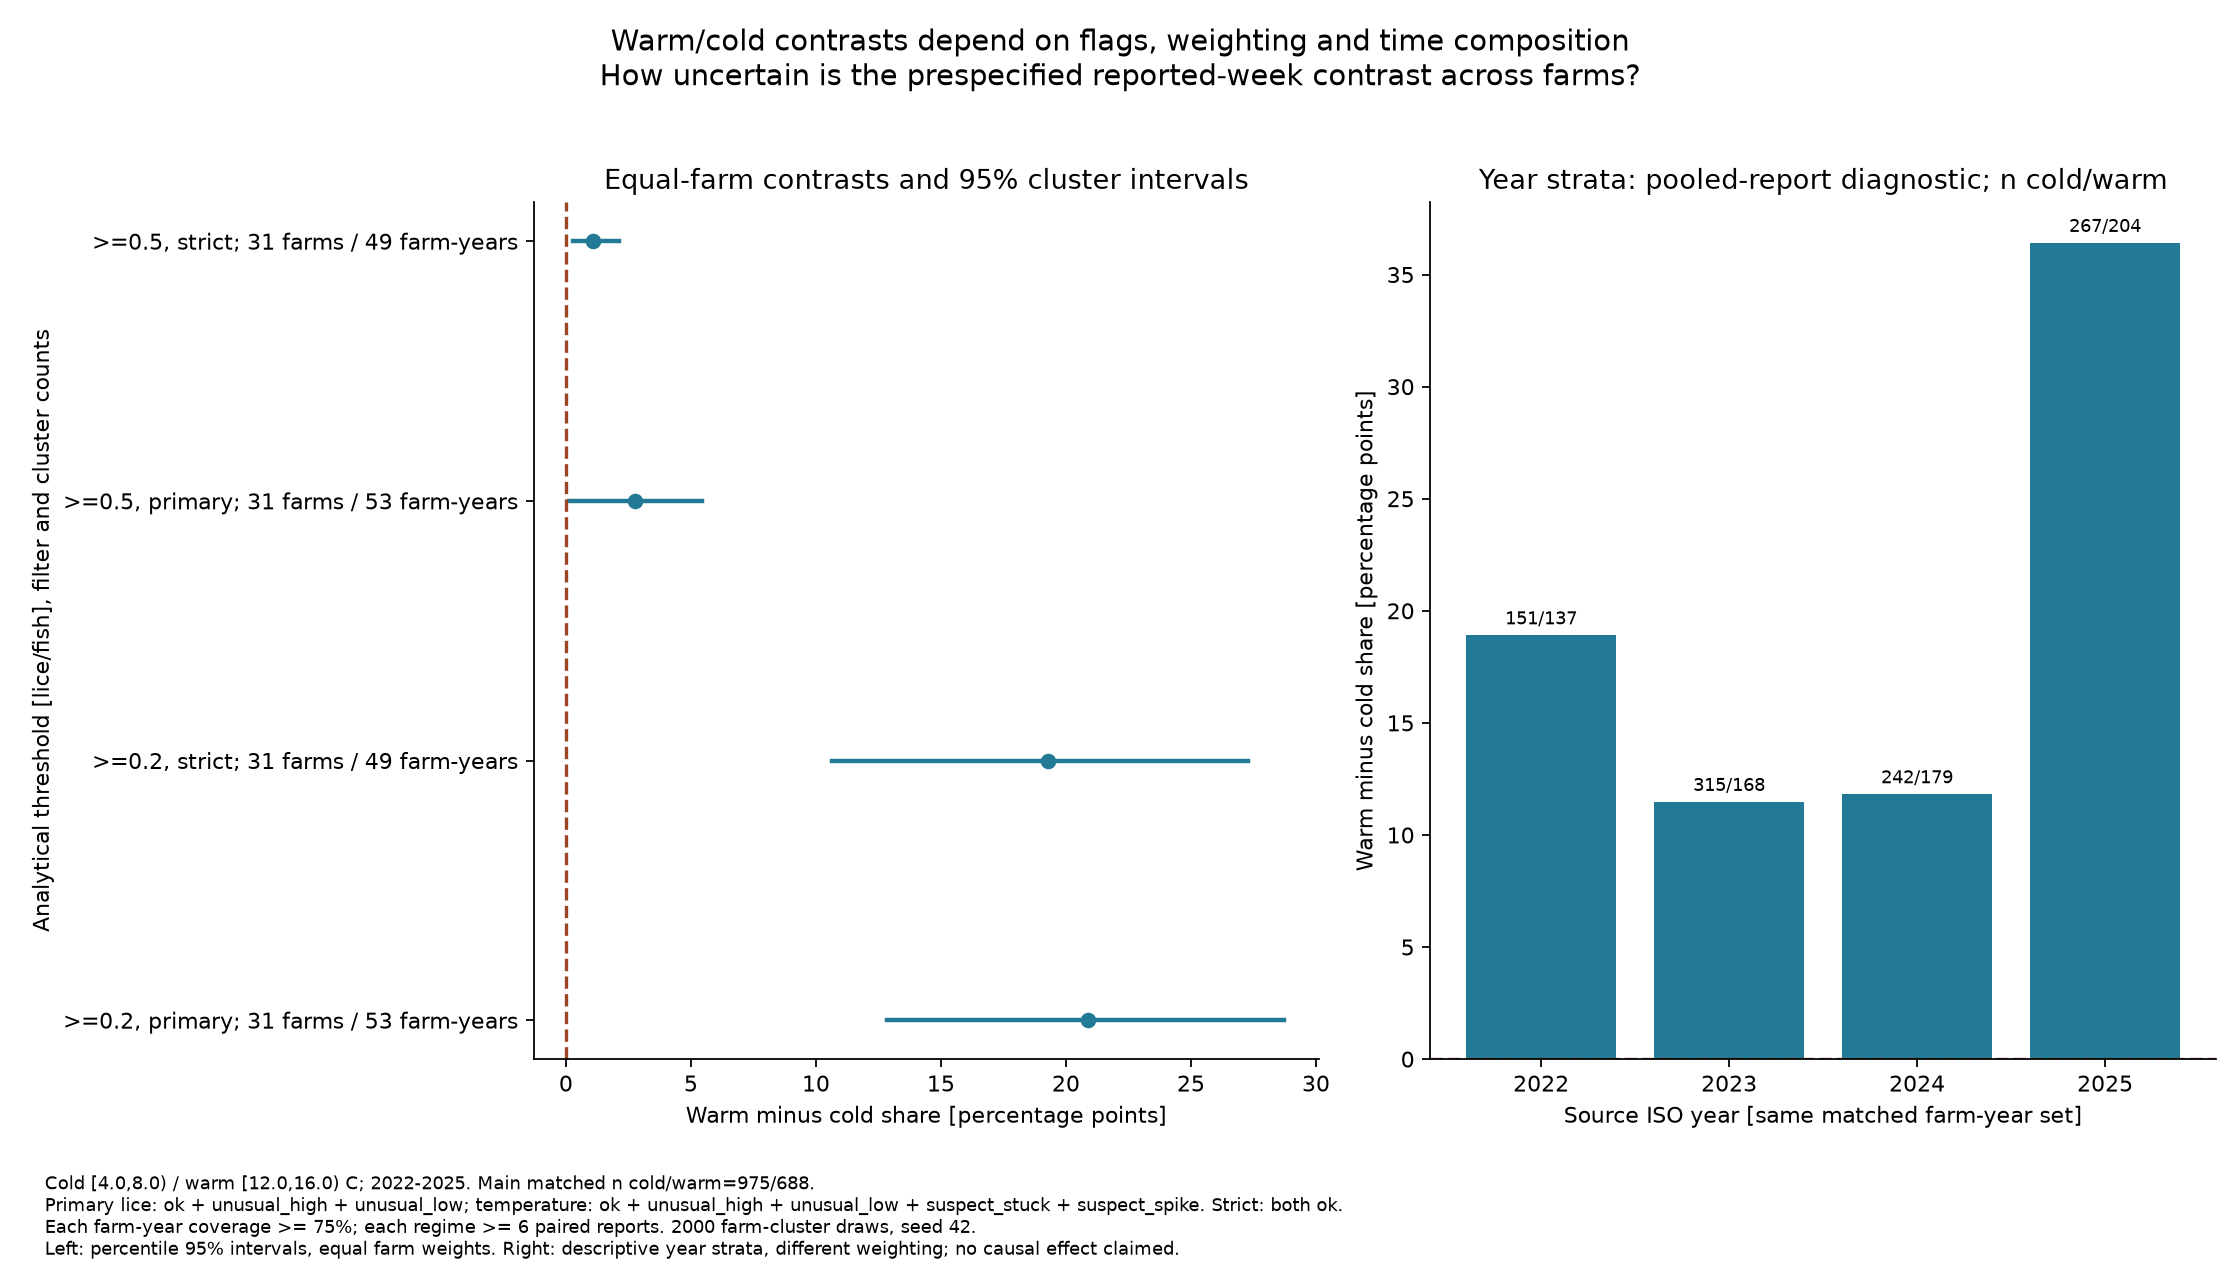

Total recorded configuration looks, including Cagatay: 121


In [10]:
from explore_egemen import clustered_comparison
look_log.add('E-COMP-PRESPEC','What comparison will supply the primary interval?',
             {'main_threshold':PARAMS.thresholds[0],'cold_half_open_c':PARAMS.cold_range_c,'warm_half_open_c':PARAMS.warm_range_c,
              'min_annual_coverage':PARAMS.min_coverage,'min_paired_reports_each_regime':PARAMS.min_regime_weeks,
              'bootstrap_unit':'farm with all its paired years','replicates':PARAMS.bootstrap_replicates,'seed':PARAMS.seed},owner='Mehmet Egemen Karagoz')
comparisons=[]
for threshold in PARAMS.thresholds:
    for strict in (False,True):
        estimate=clustered_comparison(con,PARAMS,threshold,strict=strict)
        comparisons.append(estimate)
        identifier='E-COMP-'+str(threshold)+'-'+estimate['filter']
        look_log.add(identifier,'What is the equal-farm warm-minus-cold difference and clustered interval?',
                     {key:estimate[key] for key in ('threshold','filter','farms','paired_farm_years','difference','interval95')},owner='Mehmet Egemen Karagoz')
        print(identifier,'farms',estimate['farms'],'paired years',estimate['paired_farm_years'],
              'difference',estimate['difference'],'95% interval',estimate['interval95'])
        print('Unmatched pooled:',estimate['unmatched_pooled'],'Matched pooled:',estimate['matched_pooled'])
        table(estimate['by_year'],['year','n_cold','n_warm','share_cold','share_warm','difference'])
        table(estimate['by_block'],['block','n_cold','n_warm','share_cold','share_warm','difference'])
        print('Same year-week overlap strata:',len(estimate['same_year_week']),'mean diagnostic difference',estimate['same_year_week_mean'])
        print('Same farm-year-block overlap strata:',len(estimate['within_farm_year_block']),'mean diagnostic difference',estimate['within_farm_year_block_mean'])
        for field in ('by_year','by_block'):
            for stratum in estimate[field]:
                key='year' if field=='by_year' else 'block'
                look_log.add(identifier+'-'+key+'-'+str(stratum[key]),'Does a time-stratum contrast reverse or weaken the main comparison?',stratum,owner='Mehmet Egemen Karagoz')
        for field in ('same_year_week','within_farm_year_block'):
            look_log.add(identifier+'-'+field,'Is there overlap when comparison groups share a narrower period?',
                         {'strata':len(estimate[field]),'mean_difference':estimate[field+'_mean'],
                          'minimum_per_regime':PARAMS.min_overlap_farms if field=='same_year_week' else PARAMS.min_stratum_regime_weeks},owner='Mehmet Egemen Karagoz')
egemen_results['comparisons']=comparisons
main_comparison=next(r for r in comparisons if r['threshold']==PARAMS.thresholds[0] and r['filter']=='primary')
if main_comparison['interval95'] is None:
    raise RuntimeError('Too few farms for the prespecified comparison interval; report insufficient support')
fig,axes=plt.subplots(1,2,figsize=(14,8))
for index,row in enumerate(comparisons):
    if row['interval95'] is not None:
        point=100*row['difference']; low,high=[100*v for v in row['interval95']]
        axes[0].plot([low,high],[index,index],color='#237a97',linewidth=2)
        axes[0].plot(point,index,'o',color='#237a97')
axes[0].set_yticks(range(len(comparisons)),['>='+str(r['threshold'])+', '+r['filter']+'; '+str(r['farms'])+' farms / '+str(r['paired_farm_years'])+' farm-years' for r in comparisons])
axes[0].axvline(0,color='#9c4524',linestyle='--')
axes[0].set(xlabel='Warm minus cold share [percentage points]',ylabel='Analytical threshold [lice/fish], filter and cluster counts',title='Equal-farm contrasts and 95% cluster intervals')
by_year=main_comparison['by_year']
axes[1].bar([str(r['year']) for r in by_year],[100*r['difference'] if r['difference'] is not None else np.nan for r in by_year],color='#237a97')
axes[1].axhline(0,color='#9c4524',linestyle='--')
for index,row in enumerate(by_year):
    if row['difference'] is not None:
        value=100*row['difference']
        axes[1].annotate(str(row['n_cold'])+'/'+str(row['n_warm']),(index,value),xytext=(0,5 if value>=0 else -10),textcoords='offset points',ha='center',fontsize=8)
axes[1].set(xlabel='Source ISO year [same matched farm-year set]',ylabel='Warm minus cold share [percentage points]',title='Year strata: pooled-report diagnostic; n cold/warm')
save_figure(fig,FIGURE_DIR,'m4_egemen_comparison.png',
            'Warm/cold contrasts depend on flags, weighting and time composition',
            'How uncertain is the prespecified reported-week contrast across farms?',
            'Cold ['+str(PARAMS.cold_range_c[0])+','+str(PARAMS.cold_range_c[1])+') / warm ['+str(PARAMS.warm_range_c[0])+','+str(PARAMS.warm_range_c[1])+') C; '+period_caption+'. Main matched n cold/warm='+str(main_comparison['matched_pooled']['n_cold'])+'/'+str(main_comparison['matched_pooled']['n_warm'])+'.\n'
            'Primary lice: '+flag_caption+'; temperature: '+' + '.join(PARAMS.primary_temperature_flags)+'. Strict: both ok.\n'
            'Each farm-year coverage >= '+coverage_label+'; each regime >= '+str(PARAMS.min_regime_weeks)+' paired reports. '+str(PARAMS.bootstrap_replicates)+' farm-cluster draws, seed '+str(PARAMS.seed)+'.\n'
            'Left: percentile 95% intervals, equal farm weights. Right: descriptive year strata, different weighting; no causal effect claimed.')
print('Total recorded configuration looks, including Cagatay:',len(look_log.entries))

## Reproducibility and decisions actually used
The database is read-only. This footer hashes every M2/M3 table and writes the
parameters, explicit look log and stage results outside the database.

In [11]:
after = snapshot_all(con)
if before != after:
    raise RuntimeError('Database contents changed during exploration')
results['database_unchanged'] = True
write_json(EVIDENCE_DIR,'m4_cagatay_results.json',results)
write_json(EVIDENCE_DIR,'m4_results.json',results)
write_json(EVIDENCE_DIR,'m4_readonly_hashes.json',{'before':before,'after':after,'equal':before==after})
look_log.write(EVIDENCE_DIR)
print('All table hashes unchanged:',len(after))
print('Recorded configuration looks:',len(look_log.entries))
print('Parameters used:',json.dumps(asdict(PARAMS),sort_keys=True))
print('M4 exploration complete: both source sections executed; submission tag requires explicit instruction.')
con.close()

All table hashes unchanged: 17
Recorded configuration looks: 121
Parameters used: {"bootstrap_replicates": 2000, "cohort": [10110, 10262, 10292, 10324, 10328, 11290, 11312, 11350, 11405, 11800, 11922, 12244, 12652, 12660, 12714, 12855, 12897, 13226, 13229, 13870, 20316, 20559, 22095, 26955, 29816, 30517, 31497, 31557, 31757, 33197, 33617, 34457, 35377, 35617, 36077, 36517, 36737, 37357, 45017, 45025], "cold_range_c": [4.0, 8.0], "end_year": 2025, "histogram_widths": [0.05, 0.1, 0.2], "min_block_coverage": 0.5, "min_coverage": 0.75, "min_overlap_farms": 3, "min_regime_weeks": 6, "min_stratum_regime_weeks": 2, "min_time_farms": 20, "primary_lice_flags": ["ok", "unusual_high", "unusual_low"], "primary_temperature_flags": ["ok", "unusual_high", "unusual_low", "suspect_stuck", "suspect_spike"], "relationship_bin_c": 2.0, "seed": 42, "selected_histogram_width": 0.1, "spring_windows": [[16, 21], [21, 26]], "start_year": 2022, "strict_lice_flags": ["ok"], "strict_temperature_flags": ["ok"], "t